# Analyzing Historical Stock/Revenue Data and Building a Dashboard

**Final Assignment – Python Project for Data Science (IBM / Coursera)**

Extract Tesla and GameStop stock and revenue data, then visualize share price and revenue with Plotly.


In [1]:
import yfinance as yf
import pandas as pd
from io import StringIO
import requests
from bs4 import BeautifulSoup
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')
print('Libraries imported successfully')

import plotly.io as pio
pio.renderers.default = "notebook_connected"
print('Plotly renderer:', pio.renderers.default)


Libraries imported successfully


Plotly renderer: notebook_connected


## Define Graphing Function

In [2]:
def make_graph(stock_data, revenue_data, stock):
    fig = make_subplots(
        rows=2, cols=1, shared_xaxes=True,
        subplot_titles=("Historical Share Price", "Historical Revenue"),
        vertical_spacing=0.3
    )
    stock_data_specific = stock_data[stock_data.Date <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data.Date <= '2021-06-14']
    fig.add_trace(
        go.Scatter(
            x=pd.to_datetime(stock_data_specific.Date),
            y=stock_data_specific.Close.astype("float"),
            name="Share Price"
        ),
        row=1, col=1
    )
    fig.add_trace(
        go.Scatter(
            x=pd.to_datetime(revenue_data_specific.Date),
            y=revenue_data_specific.Revenue.astype("float"),
            name="Revenue"
        ),
        row=2, col=1
    )
    fig.update_xaxes(title_text="Date", row=1, col=1)
    fig.update_xaxes(title_text="Date", row=2, col=1)
    fig.update_yaxes(title_text="Price ($US)", row=1, col=1)
    fig.update_yaxes(title_text="Revenue ($US Millions)", row=2, col=1)
    fig.update_layout(
        showlegend=False,
        height=900,
        title=stock,
        xaxis_rangeslider_visible=True
    )
    # Embed interactive Plotly HTML so output is visible in the saved notebook
    from IPython.display import HTML, display, Image
    display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False)))
    try:
        png_bytes = fig.to_image(format="png", width=900, height=900, scale=1)
        display(Image(data=png_bytes))
    except Exception as e:
        print(f"PNG export skipped: {e}")


## Question 1: Use yfinance to Extract Stock Data

In [3]:
tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period="max")
tesla_data.reset_index(inplace=True)
tesla_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data

In [4]:
def scrape_revenue(url, company_name, fallback_urls=None):
    """Download revenue HTML (Macrotrends or IBM course mirrors) and return Date/Revenue frame."""
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    }
    candidates = [url] + list(fallback_urls or [])
    html = None
    used = None
    for candidate in candidates:
        try:
            resp = requests.get(candidate, headers=headers, timeout=30)
            if resp.status_code == 200 and "Just a moment" not in resp.text and len(resp.text) > 5000:
                html = resp.text
                used = candidate
                break
            print(f"Skip {candidate} status={resp.status_code} len={len(resp.text)}")
        except Exception as e:
            print(f"Request failed for {candidate}: {e}")
    if html is None:
        raise RuntimeError(f"Could not download revenue page for {company_name}")
    print(f"Loaded {company_name} revenue from: {used}")

    soup = BeautifulSoup(html, "html.parser")
    tables = pd.read_html(StringIO(html))
    revenue = None
    for table in tables:
        if table.shape[1] < 2:
            continue
        candidate_df = table.iloc[:, :2].copy()
        candidate_df.columns = ["Date", "Revenue"]
        date_str = candidate_df["Date"].astype(str)
        if date_str.str.contains(r"\d{4}-\d{2}-\d{2}", regex=True).any():
            revenue = candidate_df
            break
    if revenue is None:
        for table in soup.find_all("table"):
            rows = []
            for tr in table.find_all("tr"):
                tds = tr.find_all("td")
                if len(tds) >= 2:
                    rows.append({"Date": tds[0].get_text(strip=True), "Revenue": tds[1].get_text(strip=True)})
            if rows and "-" in str(rows[0]["Date"]):
                revenue = pd.DataFrame(rows)
                break
    if revenue is None:
        raise RuntimeError(f"Revenue table not found for {company_name}")

    revenue["Revenue"] = (
        revenue["Revenue"].astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )
    revenue = revenue[revenue["Revenue"].notna()]
    revenue = revenue[~revenue["Revenue"].isin(["", "nan", "None"])]
    revenue.reset_index(drop=True, inplace=True)
    return revenue

tesla_url = "https://www.macrotrends.net/stocks/charts/TSLA/tesla/revenue"
tesla_fallbacks = [
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm",
]
tesla_revenue = scrape_revenue(tesla_url, "Tesla", tesla_fallbacks)
tesla_revenue.tail()


Skip https://www.macrotrends.net/stocks/charts/TSLA/tesla/revenue status=403 len=5858


Loaded Tesla revenue from: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm


,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
51,2009-09-30,46
52,2009-06-30,27


## Question 3: Use yfinance to Extract Stock Data

In [5]:
gme = yf.Ticker("GME")
gme_data = gme.history(period="max")
gme_data.reset_index(inplace=True)
gme_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658001,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662209,1.603296,1.662209,6892800,0.0,0.0


## Question 4: Use Webscraping to Extract GME Revenue Data

In [6]:
gme_url = "https://www.macrotrends.net/stocks/charts/GME/gamestop/revenue"
gme_fallbacks = [
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html",
]
gme_revenue = scrape_revenue(gme_url, "GameStop", gme_fallbacks)
gme_revenue.tail()


Skip https://www.macrotrends.net/stocks/charts/GME/gamestop/revenue status=403 len=5864


Loaded GameStop revenue from: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html


,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Question 5: Plot Tesla Stock Graph

Use the `make_graph` function to graph the Tesla Stock Data. The graph will only show data up to June 2021.

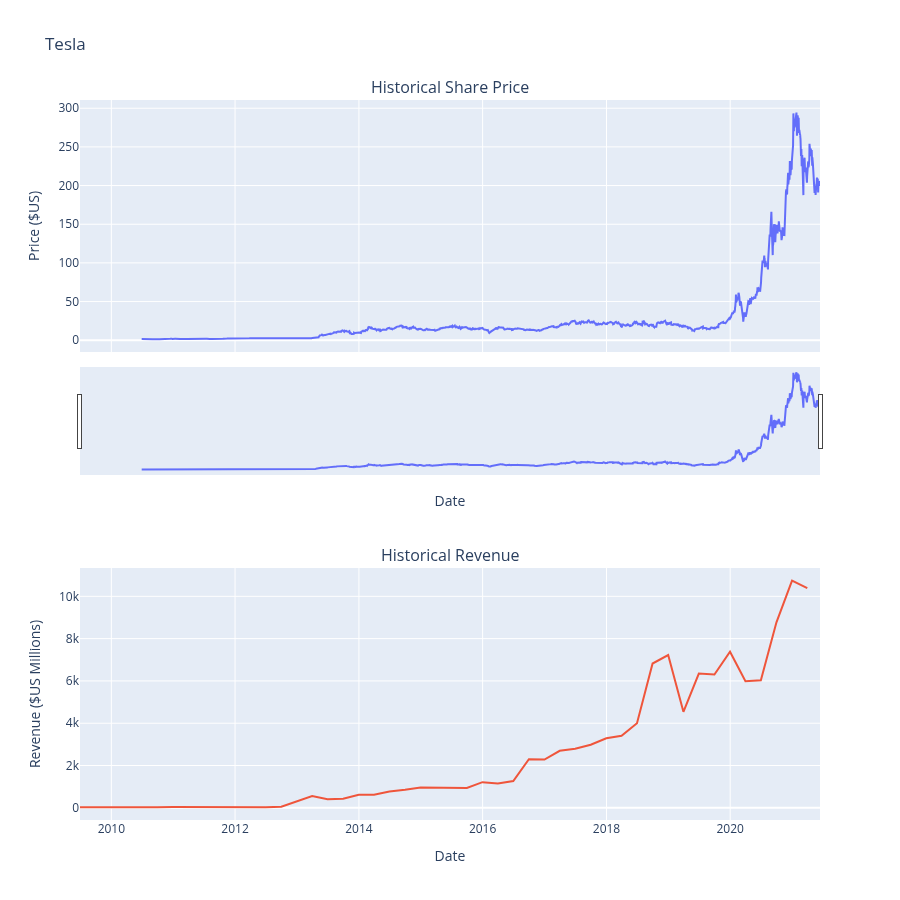

In [7]:
make_graph(tesla_data, tesla_revenue, 'Tesla')


## Question 6: Plot GameStop Stock Graph

Use the `make_graph` function to graph the GameStop Stock Data. The graph will only show data up to June 2021.

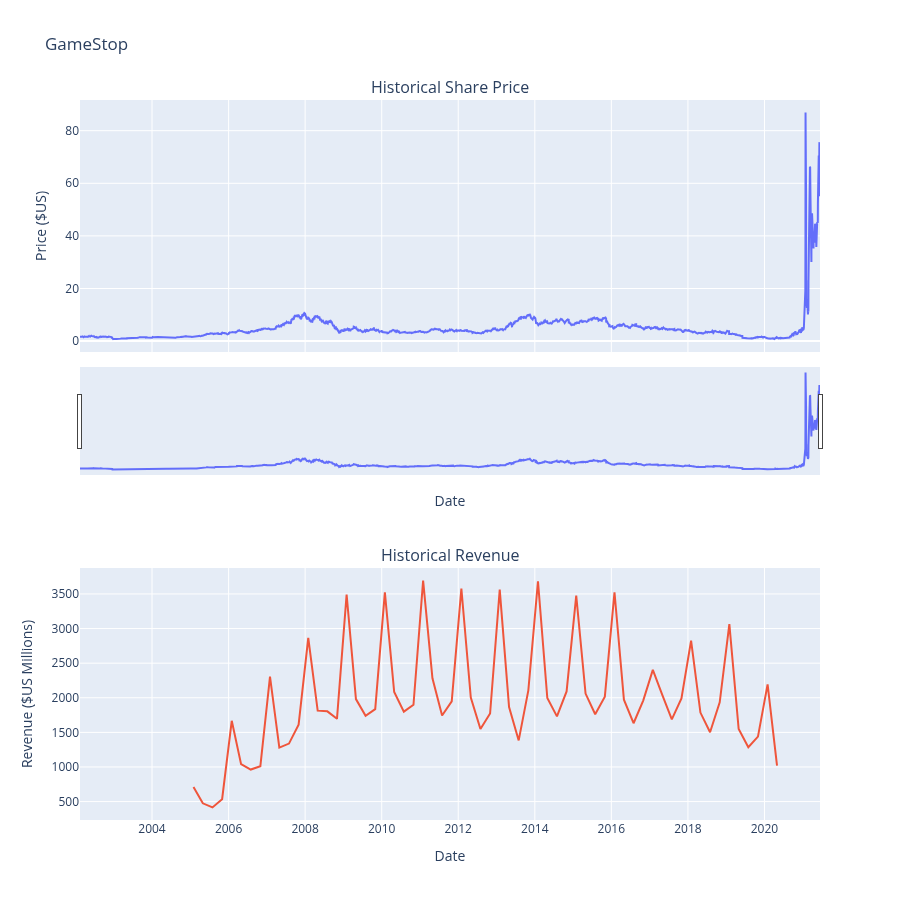

In [8]:
make_graph(gme_data, gme_revenue, 'GameStop')
